# CRM Sales Pipeline Analytics — Exploratory Data Analysis

## Project Objective

The objective of this analysis is to explore CRM sales pipeline data and identify
patterns in sales performance, product performance, customer behavior, sales-team
performance, and sales-cycle duration.

### Business Questions

- What is the overall sales performance?
- How does revenue change over time?
- Which products generate the most revenue?
- Which sales agents, managers, and regions perform best?
- Which customers and sectors contribute the most revenue?
- How long does it take to close opportunities?
- What patterns exist in the current open sales pipeline?

### Tools

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Environment ready!")

Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.6
NumPy version: 2.5.3
Environment ready!


In [3]:
from pathlib import Path

project_root = Path.cwd().parent
raw_data_path = project_root / "Raw_Data"

print("Project root:", project_root)
print("Raw data folder:", raw_data_path)
print("Folder exists:", raw_data_path.exists())

print("\nFiles available:")
for file in raw_data_path.iterdir():
    print(file.name)
    

Project root: e:\BA Projects\CRM_Sales_Pipeline_Analytics
Raw data folder: e:\BA Projects\CRM_Sales_Pipeline_Analytics\Raw_Data
Folder exists: True

Files available:
accounts.xlsx
CSV
products.xlsx
sales_pipeline.xlsx
sales_teams.xlsx


## 1. Data Loading and Initial Inspection

The project consists of four related CRM datasets:

- **sales_pipeline** — opportunity-level sales transactions
- **accounts** — customer/account information
- **sales_teams** — sales-agent, manager, and regional assignments
- **products** — product and pricing information

The raw Excel files are loaded into Pandas DataFrames for validation,
cleaning, exploratory analysis, and visualization.

In [4]:
# File paths
sales_pipeline_file = raw_data_path / "sales_pipeline.xlsx"
accounts_file = raw_data_path / "accounts.xlsx"
sales_teams_file = raw_data_path / "sales_teams.xlsx"
products_file = raw_data_path / "products.xlsx"

# Load Excel files
sales_pipeline = pd.read_excel(sales_pipeline_file)
accounts = pd.read_excel(accounts_file)
sales_teams = pd.read_excel(sales_teams_file)
products = pd.read_excel(products_file)

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [5]:
print("sales_pipeline:", sales_pipeline.shape)
print("accounts:", accounts.shape)
print("sales_teams:", sales_teams.shape)
print("products:", products.shape)

sales_pipeline: (8800, 8)
accounts: (85, 7)
sales_teams: (35, 3)
products: (7, 3)


## 2. Initial Data Inspection

Before cleaning and analysis, the datasets are inspected to understand their
structure, column names, sample records, data types, and missing values.

In [6]:
print("SALES PIPELINE COLUMNS")
print(sales_pipeline.columns.tolist())

print("\nACCOUNTS COLUMNS")
print(accounts.columns.tolist())

print("\nSALES TEAMS COLUMNS")
print(sales_teams.columns.tolist())

print("\nPRODUCTS COLUMNS")
print(products.columns.tolist())

SALES PIPELINE COLUMNS
['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage', 'engage_date', 'close_date', 'close_value']

ACCOUNTS COLUMNS
['account', 'sector', 'year_established', 'revenue', 'employees', 'office_location', 'subsidiary_of']

SALES TEAMS COLUMNS
['sales_agent', 'manager', 'regional_office']

PRODUCTS COLUMNS
['product', 'series', 'sales_price']


In [7]:
print("SALES PIPELINE")
display(sales_pipeline.head())

print("\nACCOUNTS")
display(accounts.head())

print("\nSALES TEAMS")
display(sales_teams.head())

print("\nPRODUCTS")
display(products.head())

SALES PIPELINE


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0



ACCOUNTS


,account,sector,year_established,revenue,employees,office_location,subsidiary_of
0,Acme Corporation,technolgy,1996,1100.04,2822,United States,NaN
1,Betasoloin,medical,1999,251.41,495,United States,NaN
2,Betatech,medical,1986,647.18,1185,Kenya,NaN
3,Bioholding,medical,2012,587.34,1356,Philipines,NaN
4,Bioplex,medical,1991,326.82,1016,United States,NaN



SALES TEAMS


,sales_agent,manager,regional_office
0,Anna Snelling,Dustin Brinkmann,Central
1,Cecily Lampkin,Dustin Brinkmann,Central
2,Versie Hillebrand,Dustin Brinkmann,Central
3,Lajuana Vencill,Dustin Brinkmann,Central
4,Moses Frase,Dustin Brinkmann,Central



PRODUCTS


,product,series,sales_price
0,GTX Basic,GTX,550
1,GTX Pro,GTX,4821
2,MG Special,MG,55
3,MG Advanced,MG,3393
4,GTX Plus Pro,GTX,5482


In [8]:
print("SALES PIPELINE")
sales_pipeline.info()

print("\nACCOUNTS")
accounts.info()

print("\nSALES TEAMS")
sales_teams.info()

print("\nPRODUCTS")
products.info()

SALES PIPELINE
<class 'pandas.DataFrame'>
RangeIndex: 8800 entries, 0 to 8799
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   opportunity_id  8800 non-null   str           
 1   sales_agent     8800 non-null   str           
 2   product         8800 non-null   str           
 3   account         7375 non-null   str           
 4   deal_stage      8800 non-null   str           
 5   engage_date     8300 non-null   datetime64[us]
 6   close_date      6711 non-null   datetime64[us]
 7   close_value     6711 non-null   float64       
dtypes: datetime64[us](2), float64(1), str(5)
memory usage: 550.1 KB

ACCOUNTS
<class 'pandas.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   account           85 non-null     str    
 1   sector            85 non-null     str    
 2   year_es

## 3. Data Quality Validation and Cleaning

Before performing exploratory analysis, the datasets are checked for missing
values, duplicate records, inconsistent text values, invalid numeric values,
and referential integrity issues.

Missing values are evaluated based on their business meaning rather than
automatically removed or replaced.

In [9]:
print("SALES PIPELINE - MISSING VALUES")
print(sales_pipeline.isna().sum())

print("\nACCOUNTS - MISSING VALUES")
print(accounts.isna().sum())

print("\nSALES TEAMS - MISSING VALUES")
print(sales_teams.isna().sum())

print("\nPRODUCTS - MISSING VALUES")
print(products.isna().sum())

SALES PIPELINE - MISSING VALUES
opportunity_id       0
sales_agent          0
product              0
account           1425
deal_stage           0
engage_date        500
close_date        2089
close_value       2089
dtype: int64

ACCOUNTS - MISSING VALUES
account              0
sector               0
year_established     0
revenue              0
employees            0
office_location      0
subsidiary_of       70
dtype: int64

SALES TEAMS - MISSING VALUES
sales_agent        0
manager            0
regional_office    0
dtype: int64

PRODUCTS - MISSING VALUES
product        0
series         0
sales_price    0
dtype: int64


In [10]:
print("MISSING ACCOUNT BY DEAL STAGE")
print(
    sales_pipeline.groupby("deal_stage")["account"]
    .apply(lambda x: x.isna().sum())
)

print("\nMISSING ENGAGE DATE BY DEAL STAGE")
print(
    sales_pipeline.groupby("deal_stage")["engage_date"]
    .apply(lambda x: x.isna().sum())
)

print("\nMISSING CLOSE DATE BY DEAL STAGE")
print(
    sales_pipeline.groupby("deal_stage")["close_date"]
    .apply(lambda x: x.isna().sum())
)

print("\nMISSING CLOSE VALUE BY DEAL STAGE")
print(
    sales_pipeline.groupby("deal_stage")["close_value"]
    .apply(lambda x: x.isna().sum())
)

MISSING ACCOUNT BY DEAL STAGE
deal_stage
Engaging       1088
Lost              0
Prospecting     337
Won               0
Name: account, dtype: int64

MISSING ENGAGE DATE BY DEAL STAGE
deal_stage
Engaging         0
Lost             0
Prospecting    500
Won              0
Name: engage_date, dtype: int64

MISSING CLOSE DATE BY DEAL STAGE
deal_stage
Engaging       1589
Lost              0
Prospecting     500
Won               0
Name: close_date, dtype: int64

MISSING CLOSE VALUE BY DEAL STAGE
deal_stage
Engaging       1589
Lost              0
Prospecting     500
Won               0
Name: close_value, dtype: int64


In [11]:
print("DUPLICATE ROWS")

print("sales_pipeline:", sales_pipeline.duplicated().sum())
print("accounts:", accounts.duplicated().sum())
print("sales_teams:", sales_teams.duplicated().sum())
print("products:", products.duplicated().sum())

DUPLICATE ROWS
sales_pipeline: 0
accounts: 0
sales_teams: 0
products: 0


In [12]:
print("DUPLICATE BUSINESS KEYS")

print(
    "Duplicate opportunity IDs:",
    sales_pipeline["opportunity_id"].duplicated().sum()
)

print(
    "Duplicate accounts:",
    accounts["account"].duplicated().sum()
)

print(
    "Duplicate sales agents:",
    sales_teams["sales_agent"].duplicated().sum()
)

print(
    "Duplicate products:",
    products["product"].duplicated().sum()
)

DUPLICATE BUSINESS KEYS
Duplicate opportunity IDs: 0
Duplicate accounts: 0
Duplicate sales agents: 0
Duplicate products: 0


In [13]:
print("DEAL STAGES")
print(sales_pipeline["deal_stage"].value_counts())

print("\nPIPELINE PRODUCTS")
print(sales_pipeline["product"].value_counts())

print("\nACCOUNT SECTORS")
print(accounts["sector"].value_counts())

print("\nACCOUNT OFFICE LOCATIONS")
print(accounts["office_location"].value_counts())

print("\nPRODUCT MASTER")
print(products["product"].value_counts())

print("\nPRODUCT SERIES")
print(products["series"].value_counts())

print("\nREGIONAL OFFICES")
print(sales_teams["regional_office"].value_counts())

print("\nMANAGERS")
print(sales_teams["manager"].value_counts())

DEAL STAGES
deal_stage
Won            4238
Lost           2473
Engaging       1589
Prospecting     500
Name: count, dtype: int64

PIPELINE PRODUCTS
product
GTX Basic         1866
MG Special        1651
GTXPro            1480
MG Advanced       1412
GTX Plus Basic    1383
GTX Plus Pro       968
GTK 500             40
Name: count, dtype: int64

ACCOUNT SECTORS
sector
retail                17
technolgy             12
medical               12
marketing              8
finance                8
software               7
entertainment          6
telecommunications     6
services               5
employment             4
Name: count, dtype: int64

ACCOUNT OFFICE LOCATIONS
office_location
United States    71
Kenya             1
Philipines        1
Japan             1
Italy             1
Norway            1
Korea             1
Jordan            1
Brazil            1
Germany           1
Panama            1
Belgium           1
Romania           1
Poland            1
China             1
Name: count, dt

In [14]:
print("PRODUCT NAMES WITH repr()")
for value in products["product"]:
    print(repr(value))

PRODUCT NAMES WITH repr()
'GTX Basic'
'GTX Pro'
'MG Special'
'MG Advanced'
'GTX Plus Pro'
'GTX Plus Basic'
'GTK 500'


In [15]:
for df in [sales_pipeline, accounts, sales_teams, products]:
    text_columns = df.select_dtypes(include="str").columns
    print(text_columns)

Index(['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage'], dtype='str')
Index(['account', 'sector', 'office_location', 'subsidiary_of'], dtype='str')
Index(['sales_agent', 'manager', 'regional_office'], dtype='str')
Index(['product', 'series'], dtype='str')


In [16]:
for df in [sales_pipeline, accounts, sales_teams, products]:
    text_columns = df.select_dtypes(include="str").columns

    for col in text_columns:
        df[col] = df[col].str.strip()

In [17]:
# Remove leading and trailing spaces from text columns
for df in [sales_pipeline, accounts, sales_teams, products]:
    text_columns = df.select_dtypes(include="str").columns

    for col in text_columns:
        df[col] = df[col].str.strip()


# Standardize known inconsistent values
sales_pipeline["product"] = sales_pipeline["product"].replace({
    "GTXPro": "GTX Pro"
})

accounts["sector"] = accounts["sector"].replace({
    "technolgy": "technology"
})

accounts["office_location"] = accounts["office_location"].replace({
    "Philipines": "Philippines"
})

print("Text cleaning completed.")

Text cleaning completed.


In [18]:
print("\nVALIDATION CHECK")

print(
    "GTXPro remaining:",
    (sales_pipeline["product"] == "GTXPro").sum()
)

print(
    "technolgy remaining:",
    (accounts["sector"] == "technolgy").sum()
)

print(
    "Philipines remaining:",
    (accounts["office_location"] == "Philipines").sum()
)


VALIDATION CHECK
GTXPro remaining: 0
technolgy remaining: 0
Philipines remaining: 0


In [19]:
# Products used in pipeline but missing from product master
unmatched_products = set(sales_pipeline["product"]) - set(products["product"])

# Sales agents used in pipeline but missing from sales team master
unmatched_agents = set(sales_pipeline["sales_agent"]) - set(sales_teams["sales_agent"])

# Populated accounts used in pipeline but missing from account master
unmatched_accounts = (
    set(sales_pipeline["account"].dropna())
    - set(accounts["account"])
)

print("Unmatched products:", unmatched_products)
print("Unmatched sales agents:", unmatched_agents)
print("Unmatched accounts:", unmatched_accounts)

Unmatched products: set()
Unmatched sales agents: set()
Unmatched accounts: set()


In [20]:
agents_without_opportunities = (
    set(sales_teams["sales_agent"])
    - set(sales_pipeline["sales_agent"])
)

print("Sales agents without opportunities:")
print(agents_without_opportunities)

print("\nCount:", len(agents_without_opportunities))

Sales agents without opportunities:
{'Natalya Ivanova', 'Carol Thompson', 'Mei-Mei Johns', 'Elizabeth Anderson', 'Carl Lin'}

Count: 5


In [21]:
print("NEGATIVE / INVALID NUMERIC VALUES")

print(
    "Negative close values:",
    (sales_pipeline["close_value"] < 0).sum()
)

print(
    "Zero close values:",
    (sales_pipeline["close_value"] == 0).sum()
)

print(
    "Non-positive account revenue:",
    (accounts["revenue"] <= 0).sum()
)

print(
    "Non-positive employee counts:",
    (accounts["employees"] <= 0).sum()
)

print(
    "Non-positive product prices:",
    (products["sales_price"] <= 0).sum()
)

NEGATIVE / INVALID NUMERIC VALUES
Negative close values: 0
Zero close values: 2473
Non-positive account revenue: 0
Non-positive employee counts: 0
Non-positive product prices: 0


In [22]:
print("CLOSE VALUE STATUS BY DEAL STAGE")

close_value_check = sales_pipeline.groupby("deal_stage").agg(
    total_deals=("opportunity_id", "count"),
    missing_close_value=("close_value", lambda x: x.isna().sum()),
    zero_close_value=("close_value", lambda x: (x == 0).sum()),
    positive_close_value=("close_value", lambda x: (x > 0).sum())
)

display(close_value_check)

CLOSE VALUE STATUS BY DEAL STAGE


,total_deals,missing_close_value,zero_close_value,positive_close_value
deal_stage,,,,
Engaging,1589,1589,0,0
Lost,2473,0,2473,0
Prospecting,500,500,0,0
Won,4238,0,0,4238


In [23]:
# Check invalid date sequence
invalid_date_sequence = sales_pipeline[
    sales_pipeline["engage_date"].notna()
    & sales_pipeline["close_date"].notna()
    & (sales_pipeline["engage_date"] > sales_pipeline["close_date"])
]

print("Deals where engage_date is after close_date:",
      len(invalid_date_sequence))

print("\nENGAGE DATE RANGE")
print("Minimum:", sales_pipeline["engage_date"].min())
print("Maximum:", sales_pipeline["engage_date"].max())

print("\nCLOSE DATE RANGE")
print("Minimum:", sales_pipeline["close_date"].min())
print("Maximum:", sales_pipeline["close_date"].max())

Deals where engage_date is after close_date: 0

ENGAGE DATE RANGE
Minimum: 2016-10-20 00:00:00
Maximum: 2017-12-27 00:00:00

CLOSE DATE RANGE
Minimum: 2017-03-01 00:00:00
Maximum: 2017-12-31 00:00:00


### Data Quality Summary

The following data-quality checks were performed before exploratory analysis:

- No exact duplicate records were found in any dataset.
- Primary/business keys are unique across all four datasets.
- Missing values in the sales pipeline were validated against deal stages and represent valid business states.
- Missing `engage_date` values occur only for Prospecting opportunities.
- Missing `close_date` and `close_value` values occur only for open opportunities.
- Zero `close_value` values correspond to Lost opportunities, while positive values correspond to Won opportunities.
- Product name `GTXPro` was standardized to `GTX Pro`.
- Sector value `technolgy` was corrected to `technology`.
- Office location `Philipines` was corrected to `Philippines`.
- All populated products, sales agents, and accounts in the sales pipeline match their corresponding master tables.
- Five sales-team members have no opportunities in the pipeline; these records were retained because they are valid master-data records.
- No invalid negative numeric values were identified.
- No opportunities have an engagement date later than their close date.
- Valid business nulls were preserved rather than replaced or removed.

## 4. Feature Engineering

New analytical features are created from the cleaned data to support
exploratory analysis and answer key business questions.

The features created in this section will help analyze sales-cycle duration,
deal outcomes, and sales performance over time.

In [24]:
sales_pipeline["sales_cycle_days"] = (sales_pipeline["close_date"] - sales_pipeline["engage_date"]).dt.days

In [25]:
sales_pipeline[
    ["engage_date", "close_date", "sales_cycle_days"]
].head(10)

,engage_date,close_date,sales_cycle_days
0,2016-10-20,2017-03-01,132.0
1,2016-10-25,2017-03-11,137.0
2,2016-10-25,2017-03-07,133.0
3,2016-10-25,2017-03-09,135.0
4,2016-10-25,2017-03-02,128.0
5,2016-10-29,2017-03-01,123.0
6,2016-10-30,2017-03-02,123.0
7,2016-11-01,2017-03-07,126.0
8,2016-11-01,2017-03-03,122.0
9,2016-11-03,NaT,NaN


In [26]:
print("Valid sales cycles:",
      sales_pipeline["sales_cycle_days"].notna().sum())

print("Missing sales cycles:",
      sales_pipeline["sales_cycle_days"].isna().sum())

print("Negative sales cycles:",
      (sales_pipeline["sales_cycle_days"] < 0).sum())

print("\nSales Cycle Summary:")
print(sales_pipeline["sales_cycle_days"].describe())

Valid sales cycles: 6711
Missing sales cycles: 2089
Negative sales cycles: 0

Sales Cycle Summary:


count    6711.000000
mean       47.985397
std        41.057665
min         1.000000
25%         8.000000
50%        45.000000
75%        85.000000
max       138.000000
Name: sales_cycle_days, dtype: float64


In [27]:
sales_pipeline["close_year"] = sales_pipeline["close_date"].dt.year

sales_pipeline["close_month"] = sales_pipeline["close_date"].dt.month

sales_pipeline["close_month_name"] = sales_pipeline["close_date"].dt.month_name()

sales_pipeline["close_year_month"] = (
    sales_pipeline["close_date"].dt.to_period("M")
)

In [28]:
sales_pipeline[
    [
        "close_date",
        "close_year",
        "close_month",
        "close_month_name",
        "close_year_month"
    ]
].head(10)

,close_date,close_year,close_month,close_month_name,close_year_month
0,2017-03-01,2017.0,3.0,March,2017-03
1,2017-03-11,2017.0,3.0,March,2017-03
2,2017-03-07,2017.0,3.0,March,2017-03
3,2017-03-09,2017.0,3.0,March,2017-03
4,2017-03-02,2017.0,3.0,March,2017-03
5,2017-03-01,2017.0,3.0,March,2017-03
6,2017-03-02,2017.0,3.0,March,2017-03
7,2017-03-07,2017.0,3.0,March,2017-03
8,2017-03-03,2017.0,3.0,March,2017-03
9,NaT,NaN,NaN,NaN,NaT


In [29]:
sales_pipeline["close_year"] = (
    sales_pipeline["close_year"].astype("Int64")
)

sales_pipeline["close_month"] = (
    sales_pipeline["close_month"].astype("Int64")
)

In [30]:
print("Close years:")
print(sales_pipeline["close_year"].value_counts().sort_index())

print("\nClose year-month:")
print(
    sales_pipeline["close_year_month"]
    .value_counts()
    .sort_index()
)

Close years:
close_year
2017    6711
Name: count, dtype: Int64

Close year-month:
close_year_month
2017-03    647
2017-04    586
2017-05    805
2017-06    641
2017-07    627
2017-08    785
2017-09    635
2017-10    566
2017-11    768
2017-12    651
Freq: M, Name: count, dtype: int64


In [31]:
sales_pipeline["deal_status"] = np.where(
    sales_pipeline["deal_stage"].isin(["Won", "Lost"]),
    "Closed",
    "Open"
)

In [32]:
print(sales_pipeline["deal_status"].value_counts())

deal_status
Closed    6711
Open      2089
Name: count, dtype: int64


In [33]:
pd.crosstab(
    sales_pipeline["deal_stage"],
    sales_pipeline["deal_status"]
)

deal_status,Closed,Open
deal_stage,,
Engaging,0,1589
Lost,2473,0
Prospecting,0,500
Won,4238,0


In [34]:
sales_pipeline["won_flag"] = (
    sales_pipeline["deal_stage"] == "Won"
).astype(int)

In [35]:
print(sales_pipeline["won_flag"].value_counts())

won_flag
0    4562
1    4238
Name: count, dtype: int64


In [36]:
pd.crosstab(
    sales_pipeline["deal_stage"],
    sales_pipeline["won_flag"]
)

won_flag,0,1
deal_stage,,
Engaging,1589,0
Lost,2473,0
Prospecting,500,0
Won,0,4238


In [37]:
sales_pipeline.info()

<class 'pandas.DataFrame'>
RangeIndex: 8800 entries, 0 to 8799
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   opportunity_id    8800 non-null   str           
 1   sales_agent       8800 non-null   str           
 2   product           8800 non-null   str           
 3   account           7375 non-null   str           
 4   deal_stage        8800 non-null   str           
 5   engage_date       8300 non-null   datetime64[us]
 6   close_date        6711 non-null   datetime64[us]
 7   close_value       6711 non-null   float64       
 8   sales_cycle_days  6711 non-null   float64       
 9   close_year        6711 non-null   Int64         
 10  close_month       6711 non-null   Int64         
 11  close_month_name  6711 non-null   str           
 12  close_year_month  6711 non-null   period[M]     
 13  deal_status       8800 non-null   str           
 14  won_flag          8800 non-null   i

In [38]:
sales_pipeline[
    [
        "opportunity_id",
        "deal_stage",
        "deal_status",
        "won_flag",
        "engage_date",
        "close_date",
        "sales_cycle_days",
        "close_year",
        "close_month",
        "close_month_name",
        "close_year_month"
    ]
].head(10)

,opportunity_id,deal_stage,deal_status,won_flag,engage_date,close_date,sales_cycle_days,close_year,close_month,close_month_name,close_year_month
0,1C1I7A6R,Won,Closed,1,2016-10-20,2017-03-01,132.0,2017,3,March,2017-03
1,Z063OYW0,Won,Closed,1,2016-10-25,2017-03-11,137.0,2017,3,March,2017-03
2,EC4QE1BX,Won,Closed,1,2016-10-25,2017-03-07,133.0,2017,3,March,2017-03
3,MV1LWRNH,Won,Closed,1,2016-10-25,2017-03-09,135.0,2017,3,March,2017-03
4,PE84CX4O,Won,Closed,1,2016-10-25,2017-03-02,128.0,2017,3,March,2017-03
5,ZNBS69V1,Won,Closed,1,2016-10-29,2017-03-01,123.0,2017,3,March,2017-03
6,9ME3374G,Won,Closed,1,2016-10-30,2017-03-02,123.0,2017,3,March,2017-03
7,7GN8Q4LL,Won,Closed,1,2016-11-01,2017-03-07,126.0,2017,3,March,2017-03
8,OLK9LKZB,Won,Closed,1,2016-11-01,2017-03-03,122.0,2017,3,March,2017-03
9,HAXMC4IX,Engaging,Open,0,2016-11-03,NaT,NaN,<NA>,<NA>,NaN,NaT


## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand sales performance,
deal outcomes, revenue patterns, product performance, sales-cycle behavior,
and relationships within the CRM sales pipeline.

The analysis focuses on identifying patterns, trends, distributions, and
potential business insights that can later be communicated through the
Power BI dashboard.

In [40]:
sales_pipeline.head(10)

,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value,sales_cycle_days,close_year,close_month,close_month_name,close_year_month,deal_status,won_flag
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0,132.0,2017,3,March,2017-03,Closed,1
1,Z063OYW0,Darcel Schlecht,GTX Pro,Isdom,Won,2016-10-25,2017-03-11,4514.0,137.0,2017,3,March,2017-03,Closed,1
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0,133.0,2017,3,March,2017-03,Closed,1
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0,135.0,2017,3,March,2017-03,Closed,1
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0,128.0,2017,3,March,2017-03,Closed,1
5,ZNBS69V1,Anna Snelling,MG Special,Ron-tech,Won,2016-10-29,2017-03-01,49.0,123.0,2017,3,March,2017-03,Closed,1
6,9ME3374G,Vicki Laflamme,MG Special,J-Texon,Won,2016-10-30,2017-03-02,57.0,123.0,2017,3,March,2017-03,Closed,1
7,7GN8Q4LL,Markita Hansen,GTX Basic,Cheers,Won,2016-11-01,2017-03-07,601.0,126.0,2017,3,March,2017-03,Closed,1
8,OLK9LKZB,Niesha Huffines,GTX Plus Basic,Zumgoity,Won,2016-11-01,2017-03-03,1026.0,122.0,2017,3,March,2017-03,Closed,1
9,HAXMC4IX,James Ascencio,MG Advanced,NaN,Engaging,2016-11-03,NaT,NaN,NaN,<NA>,<NA>,NaN,NaT,Open,0


In [41]:
total_opportunities = sales_pipeline["opportunity_id"].nunique()

won_opportunities = (
    sales_pipeline["deal_stage"] == "Won"
).sum()

lost_opportunities = (
    sales_pipeline["deal_stage"] == "Lost"
).sum()

open_opportunities = (
    sales_pipeline["deal_status"] == "Open"
).sum()

closed_opportunities = (
    sales_pipeline["deal_status"] == "Closed"
).sum()

print("Total Opportunities:", total_opportunities)
print("Won Opportunities:", won_opportunities)
print("Lost Opportunities:", lost_opportunities)
print("Open Opportunities:", open_opportunities)
print("Closed Opportunities:", closed_opportunities)

Total Opportunities: 8800
Won Opportunities: 4238
Lost Opportunities: 2473
Open Opportunities: 2089
Closed Opportunities: 6711


In [47]:
win_rate = (
    won_opportunities / closed_opportunities
) * 100

won_revenue = sales_pipeline.loc[
    sales_pipeline["deal_stage"] == "Won",
    "close_value"
].sum()

average_won_deal = sales_pipeline.loc[
    sales_pipeline["deal_stage"] == "Won",
    "close_value"
].mean()

print(f"Win Rate: {win_rate:.2f}%")
print(f"Won Revenue: ${won_revenue:,.2f}")
print(f"Average Won Deal Value: ${average_won_deal:,.2f}")

Win Rate: 63.15%
Won Revenue: $10,005,534.00
Average Won Deal Value: $2,360.91


### Overall Pipeline Performance

The CRM pipeline contains **8,800 opportunities**, of which **6,711 have reached
a final outcome** and **2,089 remain open**.

Among closed opportunities, **4,238 were won** and **2,473 were lost**, resulting
in a **63.15% closed-deal win rate**.

Won opportunities generated approximately **$10.01 million in revenue**, with an
**average won deal value of $2,360.91**.

These metrics establish the overall sales-performance baseline for the subsequent
product, time, sales-team, customer, and sales-cycle analyses.

In [48]:
stage_distribution = (
    sales_pipeline["deal_stage"]
    .value_counts()
    .to_frame(name="opportunities")
)

stage_distribution["percentage"] = (
    stage_distribution["opportunities"]
    / total_opportunities
    * 100
).round(2)

stage_distribution

,opportunities,percentage
deal_stage,,
Won,4238,48.16
Lost,2473,28.10
Engaging,1589,18.06
Prospecting,500,5.68


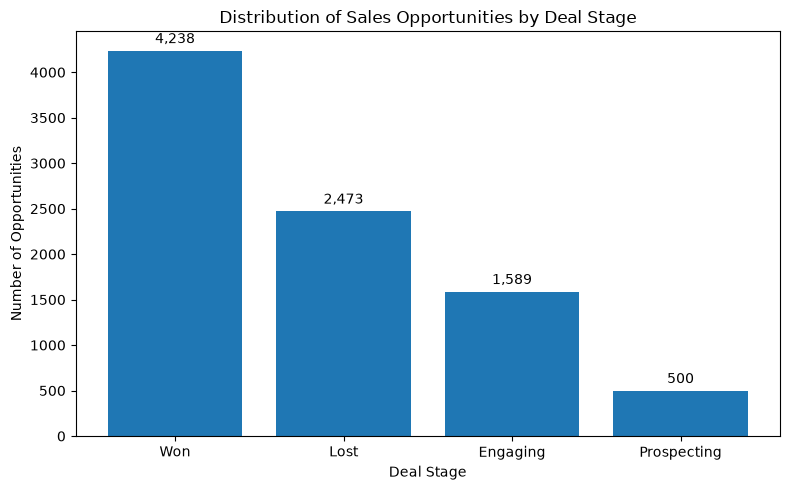

In [55]:
stage_counts = sales_pipeline["deal_stage"].value_counts()

plt.figure(figsize=(8,5))

bars = plt.bar(stage_counts.index, stage_counts.values)

plt.title("Distribution of Sales Opportunities by Deal Stage")
plt.xlabel("Deal Stage")
plt.ylabel("Number of Opportunities")
plt.bar_label(
    bars,
    labels=[f"{value:,}" for value in stage_counts.values],
    padding=3
)
plt.tight_layout()

plt.show()

# Monthly Won Revenue Trend

In [56]:
monthly_revenue = (
    sales_pipeline[sales_pipeline["deal_stage"]=="Won"].groupby("close_year_month")["close_value"].sum()
)

monthly_revenue

close_year_month
2017-03    1134672.0
2017-04     721932.0
2017-05    1025713.0
2017-06    1338466.0
2017-07     696932.0
2017-08    1050059.0
2017-09    1235264.0
2017-10     731980.0
2017-11     938943.0
2017-12    1131573.0
Freq: M, Name: close_value, dtype: float64

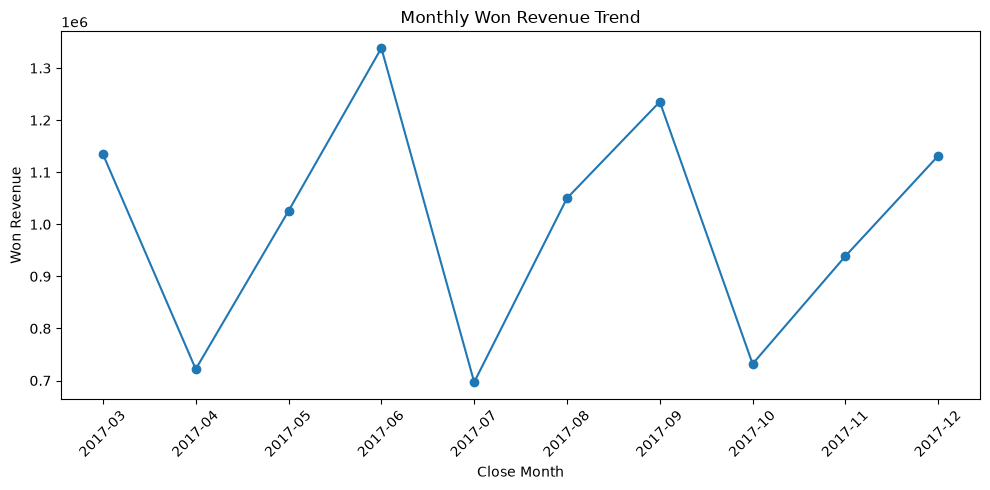

In [57]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Won Revenue Trend")
plt.xlabel("Close Month")
plt.ylabel("Won Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Month-over-Month Revenue Growth

In [69]:
monthly_revenue_analysis = pd.DataFrame({
    "revenue": monthly_revenue
})

monthly_revenue_analysis["previous_month_revenue"] = (
    monthly_revenue_analysis["revenue"].shift(1)
)

monthly_revenue_analysis["mom_growth_pct"] = (
    monthly_revenue_analysis["revenue"].pct_change() * 100
).round(2)

monthly_revenue_analysis

,revenue,previous_month_revenue,mom_growth_pct
close_year_month,,,
2017-03,1134672.0,NaN,NaN
2017-04,721932.0,1134672.0,-36.38
2017-05,1025713.0,721932.0,42.08
2017-06,1338466.0,1025713.0,30.49
2017-07,696932.0,1338466.0,-47.93
2017-08,1050059.0,696932.0,50.67
2017-09,1235264.0,1050059.0,17.64
2017-10,731980.0,1235264.0,-40.74
2017-11,938943.0,731980.0,28.27


In [70]:
highest_growth_month = (
    monthly_revenue_analysis["mom_growth_pct"].idxmax()
)

highest_growth_pct = (
    monthly_revenue_analysis["mom_growth_pct"].max()
)

largest_decline_month = (
    monthly_revenue_analysis["mom_growth_pct"].idxmin()
)

largest_decline_pct = (
    monthly_revenue_analysis["mom_growth_pct"].min()
)

print(
    f"Highest MoM Growth: {highest_growth_month} "
    f"({highest_growth_pct:.2f}%)"
)

print(
    f"Largest MoM Decline: {largest_decline_month} "
    f"({largest_decline_pct:.2f}%)"
)

Highest MoM Growth: 2017-08 (50.67%)
Largest MoM Decline: 2017-07 (-47.93%)


### Monthly Revenue Trend Insight

Won revenue showed substantial month-to-month variation rather than a consistent
upward or downward trend.

- **June 2017** generated the highest monthly won revenue at approximately
  **$1.34 million**.
- The largest month-over-month decline occurred in **July 2017**, when revenue
  decreased by **47.93%** compared with June.
- Revenue then recovered strongly in **August 2017**, recording the highest
  month-over-month growth of **50.67%**.
- Additional fluctuations occurred later in the year, including a **40.74%**
  decline in October followed by revenue growth in November and December.

Overall, monthly sales revenue was volatile during the observed period, suggesting
that revenue performance was influenced by variations in deal closures rather
than following a stable monthly growth pattern.

## Product Performance Analysis

In [73]:
product_performance = ( sales_pipeline[sales_pipeline["deal_stage"]=="Won"
                    ].groupby("product").
                    agg(
                        won_deals=("opportunity_id","count"),
                        won_revenue=("close_value","sum"),
                        average_won_deal=("close_value","mean")
                    ).
                    sort_values("won_revenue",ascending=False)  
                    )

product_performance

,won_deals,won_revenue,average_won_deal
product,,,
GTX Pro,729,3510578.0,4815.607682
GTX Plus Pro,479,2629651.0,5489.876827
MG Advanced,654,2216387.0,3388.970948
GTX Plus Basic,653,705275.0,1080.053599
GTX Basic,915,499263.0,545.642623
GTK 500,15,400612.0,26707.466667
MG Special,793,43768.0,55.192938


# Product Revenue Contribution

In [74]:
product_performance["revenue_share_pct"] = (
    product_performance["won_revenue"]
    / won_revenue
    * 100
).round(2)

product_performance

,won_deals,won_revenue,average_won_deal,revenue_share_pct
product,,,,
GTX Pro,729,3510578.0,4815.607682,35.09
GTX Plus Pro,479,2629651.0,5489.876827,26.28
MG Advanced,654,2216387.0,3388.970948,22.15
GTX Plus Basic,653,705275.0,1080.053599,7.05
GTX Basic,915,499263.0,545.642623,4.99
GTK 500,15,400612.0,26707.466667,4.00
MG Special,793,43768.0,55.192938,0.44


In [75]:
print(
    "Total Revenue Share:",
    product_performance["revenue_share_pct"].sum()
)

Total Revenue Share: 100.0


# Calculate Product Win Rate

In [76]:
product_win_rate = (
    sales_pipeline[
        sales_pipeline["deal_stage"].isin(["Won", "Lost"])
    ]
    .groupby("product")["deal_stage"]
    .agg(
        closed_deals="count",
        won_deals=lambda x: (x == "Won").sum()
    )
)

product_win_rate["win_rate_pct"] = (
    product_win_rate["won_deals"]
    / product_win_rate["closed_deals"]
    * 100
).round(2)

product_win_rate

,closed_deals,won_deals,win_rate_pct
product,,,
GTK 500,25,15,60.00
GTX Basic,1436,915,63.72
GTX Plus Basic,1051,653,62.13
GTX Plus Pro,745,479,64.30
GTX Pro,1147,729,63.56
MG Advanced,1084,654,60.33
MG Special,1223,793,64.84


In [77]:
product_analysis = product_performance.join(
    product_win_rate[["closed_deals", "win_rate_pct"]]
)

product_analysis

,won_deals,won_revenue,average_won_deal,revenue_share_pct,closed_deals,win_rate_pct
product,,,,,,
GTX Pro,729,3510578.0,4815.607682,35.09,1147,63.56
GTX Plus Pro,479,2629651.0,5489.876827,26.28,745,64.30
MG Advanced,654,2216387.0,3388.970948,22.15,1084,60.33
GTX Plus Basic,653,705275.0,1080.053599,7.05,1051,62.13
GTX Basic,915,499263.0,545.642623,4.99,1436,63.72
GTK 500,15,400612.0,26707.466667,4.00,25,60.00
MG Special,793,43768.0,55.192938,0.44,1223,64.84


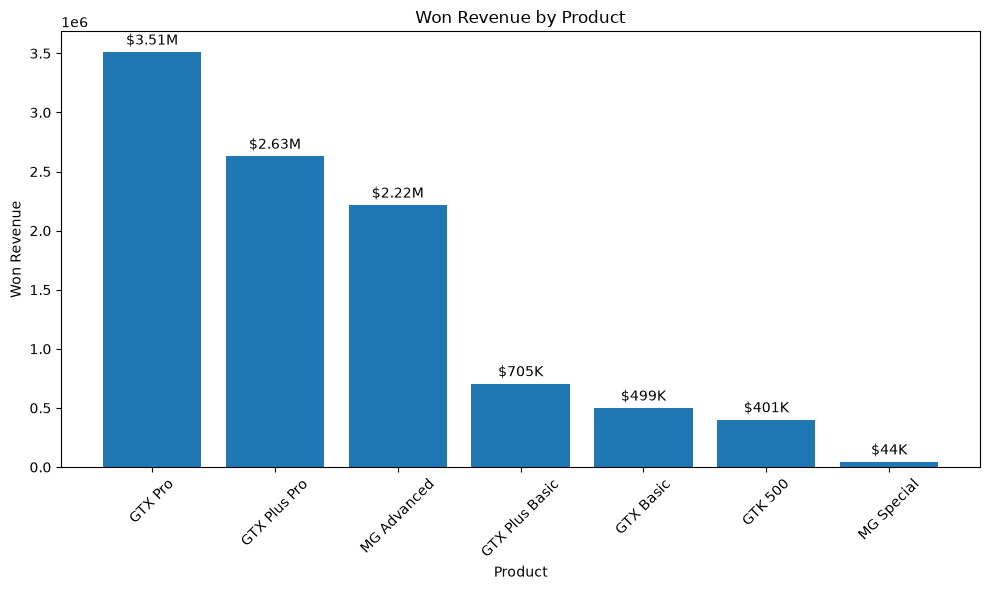

In [78]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    product_analysis.index,
    product_analysis["won_revenue"]
)

plt.title("Won Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Won Revenue")

plt.xticks(rotation=45)

plt.bar_label(
    bars,
    labels=[
        f"${value / 1_000_000:.2f}M"
        if value >= 1_000_000
        else f"${value / 1_000:.0f}K"
        for value in product_analysis["won_revenue"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

# Top 3 Product Revenue Concentration

In [79]:
top_3_revenue_share = (
    product_analysis
    .head(3)["revenue_share_pct"]
    .sum()
)

print(f"Top 3 Products Revenue Share: {top_3_revenue_share:.2f}%")

Top 3 Products Revenue Share: 83.52%


### Product Performance Insight

Product revenue is highly concentrated among a small number of products.

- **GTX Pro** is the highest-revenue product, generating approximately
  **$3.51 million**, or **35.09% of total won revenue**.
- **GTX Plus Pro** and **MG Advanced** contribute another **26.28%** and
  **22.15%**, respectively.
- Together, the **top three products generate 83.52% of total won revenue**,
  indicating substantial revenue concentration.
- **GTX Basic** recorded the highest number of won deals (**915**) but contributed
  only **4.99% of revenue**, showing that high sales volume does not necessarily
  translate into high revenue.
- **GTK 500** recorded only **15 won deals**, but its average won deal value was
  approximately **$26.7K**, making it a low-volume, high-value product.
- **MG Special** achieved the highest closed-deal win rate at **64.84%**, but
  contributed only **0.44% of total won revenue** because of its low average
  deal value.

Overall, product performance is driven by a combination of deal volume, deal
value, and conversion rate rather than any single metric.

# Start Sales Cycle Analysis

In [80]:
closed_deals_df = sales_pipeline[
    sales_pipeline["deal_stage"].isin(["Won", "Lost"])
].copy()

closed_deals_df[
    ["deal_stage", "sales_cycle_days"]
].groupby("deal_stage").describe()

sales_cycle_days                                                   
                      count       mean        std  min  25%   50%   75%    max
deal_stage                                                                    
Lost                 2473.0  41.479175  40.041176  1.0  7.0  14.0  79.0  138.0
Won                  4238.0  51.781973  41.171603  1.0  9.0  57.0  88.0  138.0

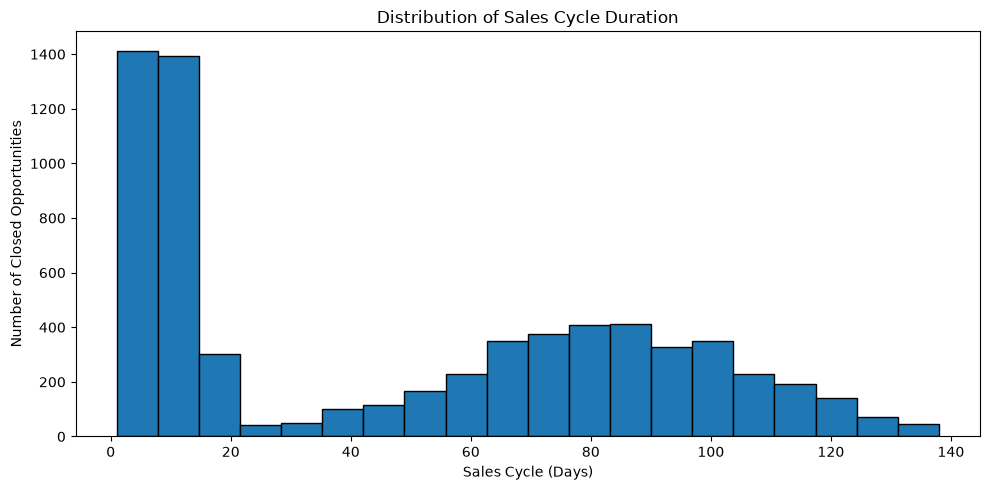

In [81]:
plt.figure(figsize=(10, 5))

plt.hist(
    closed_deals_df["sales_cycle_days"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Sales Cycle Duration")
plt.xlabel("Sales Cycle (Days)")
plt.ylabel("Number of Closed Opportunities")

plt.tight_layout()
plt.show()

# Compare Won vs Lost Sales Cycles

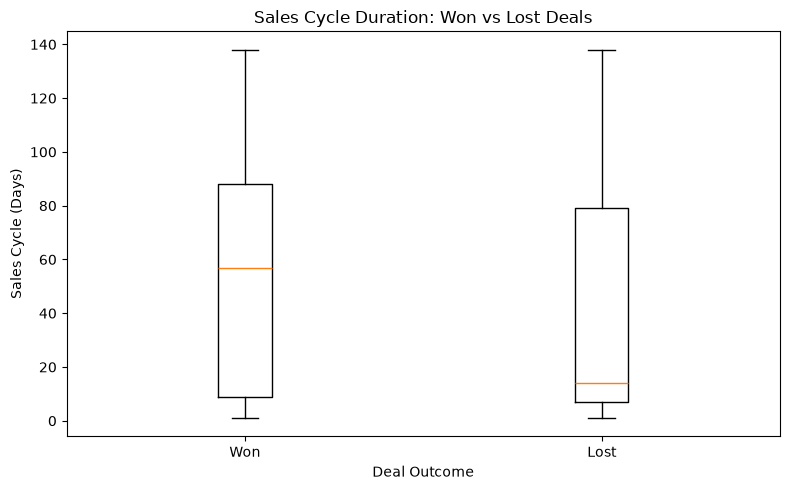

In [82]:
won_cycle = closed_deals_df.loc[
    closed_deals_df["deal_stage"] == "Won",
    "sales_cycle_days"
]

lost_cycle = closed_deals_df.loc[
    closed_deals_df["deal_stage"] == "Lost",
    "sales_cycle_days"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [won_cycle, lost_cycle],
    tick_labels=["Won", "Lost"]
)

plt.title("Sales Cycle Duration: Won vs Lost Deals")
plt.xlabel("Deal Outcome")
plt.ylabel("Sales Cycle (Days)")

plt.tight_layout()
plt.show()

### Sales Cycle Insight

Sales-cycle duration varies substantially across closed opportunities and shows
a non-uniform distribution, with concentrations of both short-cycle and
longer-cycle deals.

- **Won deals** have an average sales cycle of approximately **51.78 days**
  and a median of **57 days**.
- **Lost deals** have a lower average sales cycle of approximately **41.48 days**
  and a much lower median of **14 days**.
- The large difference between the mean and median for lost deals indicates that
  some longer-running lost opportunities increase the average duration.
- Both won and lost opportunities can remain active for extended periods, with
  observed sales cycles ranging from **1 to 138 days**.

Overall, won opportunities are associated with longer observed sales cycles than
lost opportunities in this dataset. This represents an association and does not
imply that longer sales cycles cause opportunities to be won.

# Start Sales Team Analysis

In [83]:
sales_team_analysis = sales_pipeline.merge(
    sales_teams,
    on="sales_agent",
    how="left",
    validate="many_to_one"
)

print("Pipeline rows before merge:", len(sales_pipeline))
print("Rows after merge:", len(sales_team_analysis))

print(
    "Missing manager after merge:",
    sales_team_analysis["manager"].isna().sum()
)

print(
    "Missing regional office after merge:",
    sales_team_analysis["regional_office"].isna().sum()
)

Pipeline rows before merge: 8800
Rows after merge: 8800
Missing manager after merge: 0
Missing regional office after merge: 0


# Sales Agent Performance

In [84]:
agent_performance = (
    sales_team_analysis
    .groupby("sales_agent")
    .agg(
        total_opportunities=("opportunity_id", "count"),
        closed_deals=("deal_stage", lambda x: x.isin(["Won", "Lost"]).sum()),
        won_deals=("deal_stage", lambda x: (x == "Won").sum()),
        won_revenue=("close_value", lambda x: x[
            sales_team_analysis.loc[x.index, "deal_stage"] == "Won"
        ].sum())
    )
)

agent_performance["win_rate_pct"] = (
    agent_performance["won_deals"]
    / agent_performance["closed_deals"]
    * 100
).round(2)

agent_performance["average_won_deal"] = (
    agent_performance["won_revenue"]
    / agent_performance["won_deals"]
).round(2)

agent_performance = agent_performance.sort_values(
    "won_revenue",
    ascending=False
)

agent_performance.head(10)

,total_opportunities,closed_deals,won_deals,won_revenue,win_rate_pct,average_won_deal
sales_agent,,,,,,
Darcel Schlecht,747,553,349,1153214.0,63.11,3304.34
Vicki Laflamme,451,347,221,478396.0,63.69,2164.69
Kary Hendrixson,438,335,209,454298.0,62.39,2173.67
Cassey Cress,346,261,163,450489.0,62.45,2763.74
Donn Cantrell,275,275,158,445860.0,57.45,2821.90
Reed Clapper,237,237,155,438336.0,65.40,2827.97
Zane Levy,349,261,161,430068.0,61.69,2671.23
Corliss Cosme,310,229,150,421036.0,65.50,2806.91
James Ascencio,267,206,135,413533.0,65.53,3063.21


- Highest Agent Win Rate

In [85]:
highest_win_rate_agent = (
    agent_performance["win_rate_pct"].idxmax()
)

highest_agent_win_rate = (
    agent_performance["win_rate_pct"].max()
)

print(
    f"Highest Agent Win Rate: {highest_win_rate_agent} "
    f"({highest_agent_win_rate:.2f}%)"
)

Highest Agent Win Rate: Hayden Neloms (70.39%)


- Manager Performance

In [86]:
manager_performance = (
    sales_team_analysis
    .groupby("manager")
    .agg(
        total_opportunities=("opportunity_id", "count"),
        closed_deals=("deal_stage", lambda x: x.isin(["Won", "Lost"]).sum()),
        won_deals=("deal_stage", lambda x: (x == "Won").sum()),
        won_revenue=("close_value", lambda x: x[
            sales_team_analysis.loc[x.index, "deal_stage"] == "Won"
        ].sum())
    )
)

manager_performance["win_rate_pct"] = (
    manager_performance["won_deals"]
    / manager_performance["closed_deals"]
    * 100
).round(2)

manager_performance["average_won_deal"] = (
    manager_performance["won_revenue"]
    / manager_performance["won_deals"]
).round(2)

manager_performance = manager_performance.sort_values(
    "won_revenue",
    ascending=False
)

manager_performance

,total_opportunities,closed_deals,won_deals,won_revenue,win_rate_pct,average_won_deal
manager,,,,,,
Melvin Marxen,1929,1418,882,2251930.0,62.20,2553.21
Summer Sewald,1701,1287,828,1964750.0,64.34,2372.89
Rocco Neubert,1327,1113,691,1960545.0,62.08,2837.26
Celia Rouche,1296,962,610,1603897.0,63.41,2629.34
Cara Losch,964,745,480,1130049.0,64.43,2354.27
Dustin Brinkmann,1583,1186,747,1094363.0,62.98,1465.01


- Regional Performance

In [87]:
region_performance = (
    sales_team_analysis
    .groupby("regional_office")
    .agg(
        total_opportunities=("opportunity_id", "count"),
        closed_deals=("deal_stage", lambda x: x.isin(["Won", "Lost"]).sum()),
        won_deals=("deal_stage", lambda x: (x == "Won").sum()),
        won_revenue=("close_value", lambda x: x[
            sales_team_analysis.loc[x.index, "deal_stage"] == "Won"
        ].sum())
    )
)

region_performance["win_rate_pct"] = (
    region_performance["won_deals"]
    / region_performance["closed_deals"]
    * 100
).round(2)

region_performance["average_won_deal"] = (
    region_performance["won_revenue"]
    / region_performance["won_deals"]
).round(2)

region_performance = region_performance.sort_values(
    "won_revenue",
    ascending=False
)

region_performance

,total_opportunities,closed_deals,won_deals,won_revenue,win_rate_pct,average_won_deal
regional_office,,,,,,
West,2997,2249,1438,3568647.0,63.94,2481.67
Central,3512,2604,1629,3346293.0,62.56,2054.20
East,2291,1858,1171,3090594.0,63.02,2639.28


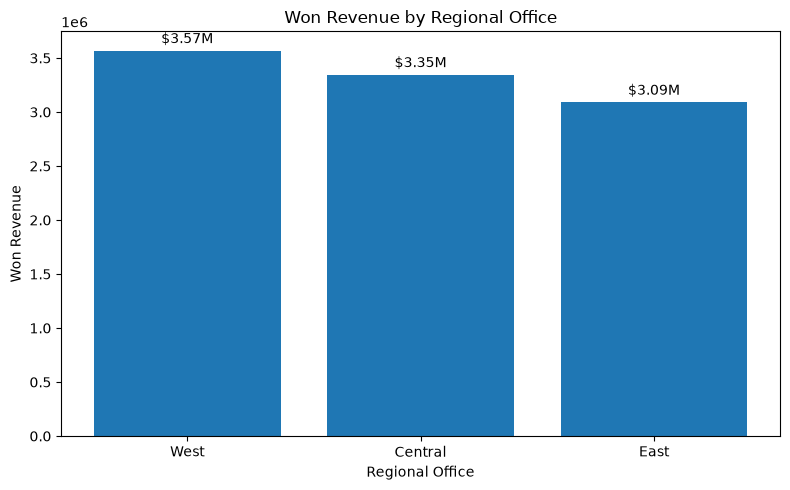

In [88]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    region_performance.index,
    region_performance["won_revenue"]
)

plt.title("Won Revenue by Regional Office")
plt.xlabel("Regional Office")
plt.ylabel("Won Revenue")

plt.bar_label(
    bars,
    labels=[
        f"${value / 1_000_000:.2f}M"
        for value in region_performance["won_revenue"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

### Sales Team Performance Insight

Sales performance varies across agents, managers, and regional offices, with
different leaders depending on the performance metric considered.

- **Darcel Schlecht** generated the highest individual won revenue at approximately
  **$1.15 million**, from **349 won deals**.
- **Hayden Neloms** recorded the highest closed-deal win rate among active sales
  agents at **70.39%**.
- At the manager level, **Melvin Marxen's team** generated the highest won revenue
  at approximately **$2.25 million**.
- **Cara Losch's team** achieved the highest manager-level win rate at **64.43%**.
- **Rocco Neubert's team** recorded the highest average won deal value among
  managers at approximately **$2,837**.
- At the regional level, **West** generated the highest won revenue at approximately
  **$3.57 million**, while **Central** handled the highest opportunity volume and
  recorded the most won deals.
- **East** generated the highest average won deal value at approximately **$2,639**.

Overall, sales performance cannot be evaluated using revenue alone. Opportunity
volume, conversion rate, and average deal value provide complementary views of
agent, manager, and regional performance.

# Start Customer & Sector Analysis

In [89]:
customer_analysis = sales_pipeline.merge(
    accounts,
    on="account",
    how="left",
    validate="many_to_one"
)

print("Pipeline rows before merge:", len(sales_pipeline))
print("Rows after merge:", len(customer_analysis))

print(
    "Pipeline opportunities with missing account:",
    sales_pipeline["account"].isna().sum()
)

print(
    "Missing sector after merge:",
    customer_analysis["sector"].isna().sum()
)

Pipeline rows before merge: 8800
Rows after merge: 8800
Pipeline opportunities with missing account: 1425
Missing sector after merge: 1425


- Top Customer Accounts by Won Revenue

In [90]:
account_performance = (
    customer_analysis[
        (customer_analysis["deal_stage"] == "Won")
        & (customer_analysis["account"].notna())
    ]
    .groupby("account")
    .agg(
        won_deals=("opportunity_id", "count"),
        won_revenue=("close_value", "sum"),
        average_won_deal=("close_value", "mean")
    )
    .sort_values(
        "won_revenue",
        ascending=False
    )
)

account_performance.head(10)

,won_deals,won_revenue,average_won_deal
account,,,
Kan-code,115,341455.0,2969.173913
Konex,108,269245.0,2493.009259
Condax,105,206410.0,1965.809524
Cheers,57,198020.0,3474.035088
Hottechi,111,194957.0,1756.369369
Goodsilron,65,182522.0,2808.030769
Treequote,65,176751.0,2719.246154
Warephase,70,170046.0,2429.228571
Xx-holding,48,169357.0,3528.270833


In [91]:
account_performance["revenue_share_pct"] = (
    account_performance["won_revenue"]
    / won_revenue
    * 100
).round(2)

top_5_account_share = (
    account_performance
    .head(5)["revenue_share_pct"]
    .sum()
)

top_10_account_share = (
    account_performance
    .head(10)["revenue_share_pct"]
    .sum()
)

print(f"Top 5 Accounts Revenue Share: {top_5_account_share:.2f}%")
print(f"Top 10 Accounts Revenue Share: {top_10_account_share:.2f}%")

Top 5 Accounts Revenue Share: 12.09%
Top 10 Accounts Revenue Share: 20.72%


In [92]:
sector_performance = (
    customer_analysis[
        (customer_analysis["deal_stage"] == "Won")
        & (customer_analysis["sector"].notna())
    ]
    .groupby("sector")
    .agg(
        won_deals=("opportunity_id", "count"),
        won_revenue=("close_value", "sum"),
        average_won_deal=("close_value", "mean")
    )
    .sort_values(
        "won_revenue",
        ascending=False
    )
)

sector_performance["revenue_share_pct"] = (
    sector_performance["won_revenue"]
    / won_revenue
    * 100
).round(2)

sector_performance

,won_deals,won_revenue,average_won_deal,revenue_share_pct
sector,,,,
retail,799,1867528.0,2337.331665,18.66
technology,671,1515487.0,2258.549925,15.15
medical,592,1359595.0,2296.613176,13.59
software,450,1077934.0,2395.408889,10.77
finance,375,950908.0,2535.754667,9.50
marketing,404,922321.0,2282.972772,9.22
entertainment,260,689007.0,2650.026923,6.89
telecommunications,285,653574.0,2293.242105,6.53
services,223,533006.0,2390.161435,5.33


- Sector Win Rate

In [93]:
sector_win_rate = (
    customer_analysis[
        customer_analysis["deal_stage"].isin(["Won", "Lost"])
    ]
    .groupby("sector")["deal_stage"]
    .agg(
        closed_deals="count",
        won_deals=lambda x: (x == "Won").sum()
    )
)

sector_win_rate["win_rate_pct"] = (
    sector_win_rate["won_deals"]
    / sector_win_rate["closed_deals"]
    * 100
).round(2)

sector_win_rate = sector_win_rate.sort_values(
    "win_rate_pct",
    ascending=False
)

sector_win_rate

,closed_deals,won_deals,win_rate_pct
sector,,,
marketing,623,404,64.85
entertainment,402,260,64.68
software,704,450,63.92
technology,1058,671,63.42
services,352,223,63.35
retail,1267,799,63.06
employment,286,179,62.59
telecommunications,456,285,62.50
medical,950,592,62.32


In [94]:
sector_analysis = sector_performance.join(
    sector_win_rate[["closed_deals", "win_rate_pct"]]
)

sector_analysis

,won_deals,won_revenue,average_won_deal,revenue_share_pct,closed_deals,win_rate_pct
sector,,,,,,
retail,799,1867528.0,2337.331665,18.66,1267,63.06
technology,671,1515487.0,2258.549925,15.15,1058,63.42
medical,592,1359595.0,2296.613176,13.59,950,62.32
software,450,1077934.0,2395.408889,10.77,704,63.92
finance,375,950908.0,2535.754667,9.50,613,61.17
marketing,404,922321.0,2282.972772,9.22,623,64.85
entertainment,260,689007.0,2650.026923,6.89,402,64.68
telecommunications,285,653574.0,2293.242105,6.53,456,62.50
services,223,533006.0,2390.161435,5.33,352,63.35


-Won Revenue by Sector

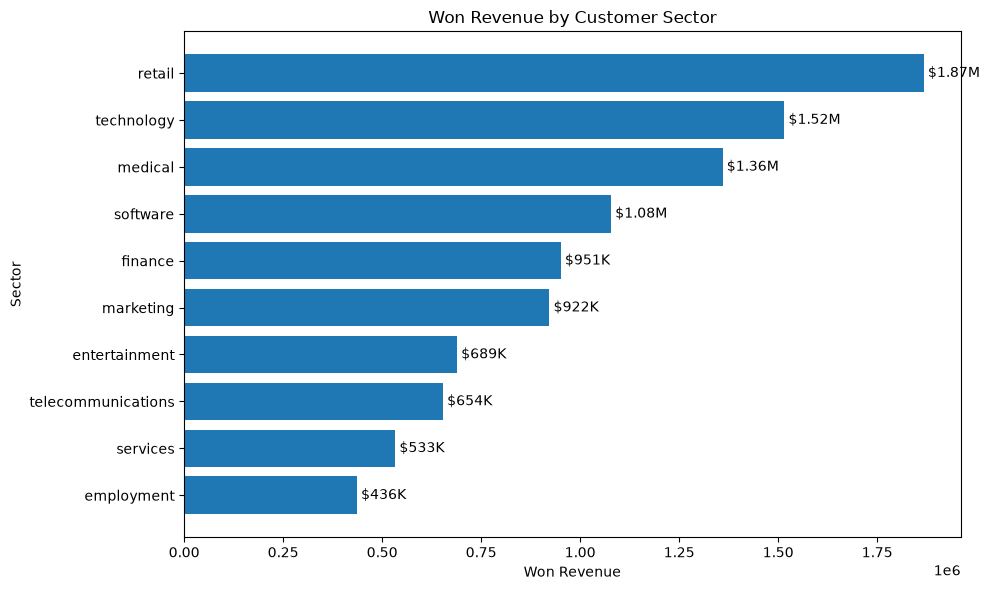

In [95]:
sector_chart = sector_analysis.sort_values(
    "won_revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    sector_chart.index,
    sector_chart["won_revenue"]
)

plt.title("Won Revenue by Customer Sector")
plt.xlabel("Won Revenue")
plt.ylabel("Sector")

plt.bar_label(
    bars,
    labels=[
        f"${value / 1_000_000:.2f}M"
        if value >= 1_000_000
        else f"${value / 1_000:.0f}K"
        for value in sector_chart["won_revenue"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

### Customer and Sector Performance Insight

Customer revenue is relatively diversified across individual accounts.

- **Kan-code** is the highest-revenue customer account, generating approximately
  **$341K** in won revenue.
- The **top 5 customer accounts contribute only 12.09%** of total won revenue,
  while the **top 10 contribute 20.72%**.
- This contrasts strongly with product performance, where the top three products
  contribute **83.52% of total won revenue**, indicating that revenue is much more
  concentrated by product than by individual customer account.

At the sector level:

- **Retail** generates the highest won revenue at approximately **$1.87 million**,
  representing **18.66% of total won revenue**.
- **Technology** and **Medical** are the next-largest sectors, contributing
  **15.15%** and **13.59%**, respectively.
- Together, Retail, Technology, and Medical contribute approximately **47.40%**
  of total won revenue.
- **Marketing** records the highest closed-deal win rate at **64.85%**.
- **Entertainment** has the highest average won deal value at approximately
  **$2,650**, despite ranking below the largest sectors in total revenue.
- **Finance** records the lowest sector win rate at **61.17%**.

Overall, sector performance is influenced by a combination of deal volume,
conversion rate, and average deal value. No single sector leads across every
performance metric.

# Start Open Pipeline Analysis

In [96]:
open_pipeline = sales_team_analysis[
    sales_team_analysis["deal_status"] == "Open"
].copy()

print("Total Open Opportunities:", len(open_pipeline))

open_stage_summary = (
    open_pipeline["deal_stage"]
    .value_counts()
    .to_frame(name="opportunities")
)

open_stage_summary["percentage"] = (
    open_stage_summary["opportunities"]
    / len(open_pipeline)
    * 100
).round(2)

open_stage_summary

Total Open Opportunities: 2089


,opportunities,percentage
deal_stage,,
Engaging,1589,76.07
Prospecting,500,23.93


- Account Identification in Open Pipeline

In [97]:
open_account_summary = pd.Series({
    "Identified Account": open_pipeline["account"].notna().sum(),
    "Missing Account": open_pipeline["account"].isna().sum()
})

open_account_percentage = (
    open_account_summary
    / len(open_pipeline)
    * 100
).round(2)

open_account_analysis = pd.DataFrame({
    "opportunities": open_account_summary,
    "percentage": open_account_percentage
})

open_account_analysis

,opportunities,percentage
Identified Account,664,31.79
Missing Account,1425,68.21


In [98]:
open_account_by_stage = (
    open_pipeline
    .assign(
        account_status=np.where(
            open_pipeline["account"].notna(),
            "Identified Account",
            "Missing Account"
        )
    )
    .groupby(
        ["deal_stage", "account_status"]
    )
    .size()
    .unstack(fill_value=0)
)

open_account_by_stage["Total"] = (
    open_account_by_stage.sum(axis=1)
)

open_account_by_stage

account_status,Identified Account,Missing Account,Total
deal_stage,,,
Engaging,501,1088,1589
Prospecting,163,337,500


In [99]:
open_account_by_stage["missing_account_pct"] = (
    open_account_by_stage["Missing Account"]
    / open_account_by_stage["Total"]
    * 100
).round(2)

open_account_by_stage["identified_account_pct"] = (
    open_account_by_stage["Identified Account"]
    / open_account_by_stage["Total"]
    * 100
).round(2)

open_account_by_stage

account_status,Identified Account,Missing Account,Total,missing_account_pct,identified_account_pct
deal_stage,,,,,
Engaging,501,1088,1589,68.47,31.53
Prospecting,163,337,500,67.40,32.60


# Open Pipeline by Product

In [100]:
open_product_summary = (
    open_pipeline
    .groupby("product")
    .agg(
        open_opportunities=("opportunity_id", "count"),
        prospecting=("deal_stage", lambda x: (x == "Prospecting").sum()),
        engaging=("deal_stage", lambda x: (x == "Engaging").sum()),
        missing_accounts=("account", lambda x: x.isna().sum())
    )
    .sort_values(
        "open_opportunities",
        ascending=False
    )
)

open_product_summary["open_pipeline_share_pct"] = (
    open_product_summary["open_opportunities"]
    / len(open_pipeline)
    * 100
).round(2)

open_product_summary

,open_opportunities,prospecting,engaging,missing_accounts,open_pipeline_share_pct
product,,,,,
GTX Basic,430,93,337,303,20.58
MG Special,428,120,308,292,20.49
GTX Pro,333,80,253,222,15.94
GTX Plus Basic,332,74,258,215,15.89
MG Advanced,328,86,242,231,15.70
GTX Plus Pro,223,47,176,154,10.67
GTK 500,15,0,15,8,0.72


# Open Pipeline by Region

In [101]:
open_region_summary = (
    open_pipeline
    .groupby("regional_office")
    .agg(
        open_opportunities=("opportunity_id", "count"),
        prospecting=("deal_stage", lambda x: (x == "Prospecting").sum()),
        engaging=("deal_stage", lambda x: (x == "Engaging").sum()),
        missing_accounts=("account", lambda x: x.isna().sum())
    )
    .sort_values(
        "open_opportunities",
        ascending=False
    )
)

open_region_summary["open_pipeline_share_pct"] = (
    open_region_summary["open_opportunities"]
    / len(open_pipeline)
    * 100
).round(2)

open_region_summary

,open_opportunities,prospecting,engaging,missing_accounts,open_pipeline_share_pct
regional_office,,,,,
Central,908,500,408,611,43.47
West,748,0,748,518,35.81
East,433,0,433,296,20.73


# Visualize Open Pipeline by Region and Stage

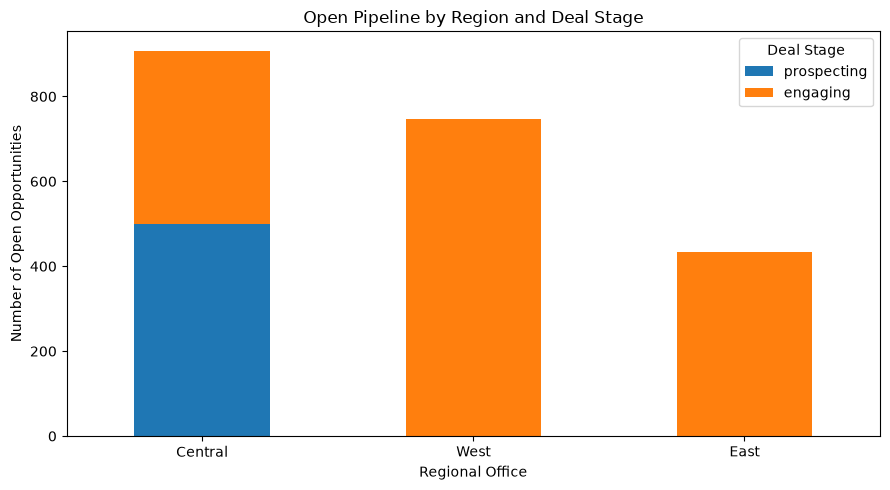

In [102]:
region_stage_chart = open_region_summary[
    ["prospecting", "engaging"]
]

region_stage_chart.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Open Pipeline by Region and Deal Stage")
plt.xlabel("Regional Office")
plt.ylabel("Number of Open Opportunities")

plt.xticks(rotation=0)

plt.legend(
    title="Deal Stage"
)

plt.tight_layout()
plt.show()

### Open Pipeline Insight

The current sales pipeline contains **2,089 open opportunities**.

- **1,589 opportunities (76.07%)** are in the Engaging stage, while
  **500 opportunities (23.93%)** remain in Prospecting.
- Only **664 open opportunities (31.79%)** have an identified customer account,
  while **1,425 (68.21%)** have no account currently recorded.
- Missing-account rates are similar across both open stages:
  **68.47% for Engaging** and **67.40% for Prospecting**.
- **GTX Basic** has the largest product-level open pipeline with **430 opportunities
  (20.58%)**, closely followed by **MG Special** with **428 (20.49%)**.
- **Central** contains the largest regional open pipeline with **908 opportunities
  (43.47%)**, followed by **West with 748 (35.81%)** and **East with 433 (20.73%)**.
- All **500 Prospecting opportunities are assigned to the Central region**.
  West and East contain only Engaging opportunities among their open deals.

The concentration of Prospecting opportunities within Central is a notable
sales-process pattern. The available data does not establish whether this reflects
regional operating practices, opportunity assignment rules, timing differences,
or another business factor, so further business context would be required before
drawing a causal conclusion.

The high proportion of open opportunities without identified accounts may also
limit customer-level pipeline analysis and should be considered when interpreting
account and sector views of the open pipeline.

In [103]:
print("=== FINAL EDA VALIDATION ===")

print("Total Opportunities:", len(sales_pipeline))
print("Closed Opportunities:", (sales_pipeline["deal_status"] == "Closed").sum())
print("Open Opportunities:", (sales_pipeline["deal_status"] == "Open").sum())

print(
    "Won Opportunities:",
    (sales_pipeline["deal_stage"] == "Won").sum()
)

print(
    "Lost Opportunities:",
    (sales_pipeline["deal_stage"] == "Lost").sum()
)

print(
    "Total Won Revenue:",
    sales_pipeline.loc[
        sales_pipeline["deal_stage"] == "Won",
        "close_value"
    ].sum()
)

print(
    "Product Revenue Reconciliation:",
    product_analysis["won_revenue"].sum()
)

print(
    "Sector Revenue Reconciliation:",
    sector_analysis["won_revenue"].sum()
)

print(
    "Regional Revenue Reconciliation:",
    region_performance["won_revenue"].sum()
)

print(
    "Open Pipeline Reconciliation:",
    open_region_summary["open_opportunities"].sum()
)

=== FINAL EDA VALIDATION ===
Total Opportunities: 8800
Closed Opportunities: 6711
Open Opportunities: 2089
Won Opportunities: 4238
Lost Opportunities: 2473
Total Won Revenue: 10005534.0
Product Revenue Reconciliation: 10005534.0
Sector Revenue Reconciliation: 10005534.0
Regional Revenue Reconciliation: 10005534.0
Open Pipeline Reconciliation: 2089


## Executive Summary

The CRM Sales Pipeline analysis evaluated **8,800 sales opportunities** across
products, customers, sales teams, regions, and deal stages to understand overall
sales performance and identify key business patterns.

### Overall Sales Performance

The pipeline contains **6,711 closed opportunities** and **2,089 open
opportunities**. Among closed deals, **4,238 were won** and **2,473 were lost**,
resulting in a **63.15% closed-deal win rate**.

Won opportunities generated approximately **$10.01 million in revenue**, with an
average won deal value of approximately **$2,361**.

### Revenue Trend

Monthly won revenue showed substantial variation rather than a consistent growth
trend. **June 2017** generated the highest monthly revenue at approximately
**$1.34 million**.

The largest month-over-month decline occurred in **July (-47.93%)**, followed by
the strongest monthly recovery in **August (+50.67%)**.

### Product Performance

Revenue is highly concentrated among a small number of products.

**GTX Pro**, **GTX Plus Pro**, and **MG Advanced** together generated
**83.52% of total won revenue**.

GTX Basic recorded the highest number of won deals, while GTK 500 demonstrated
a low-volume, high-value sales pattern.

### Sales Cycle

Won opportunities had an average sales cycle of approximately **51.78 days**
compared with **41.48 days for lost opportunities**.

The median sales cycle was **57 days for won deals** and **14 days for lost
deals**, indicating substantial differences in the observed duration of successful
and unsuccessful opportunities.

This represents an association within the dataset and does not imply that longer
sales cycles cause opportunities to be won.

### Sales Team and Regional Performance

**Darcel Schlecht** generated the highest individual won revenue at approximately
**$1.15 million**, while **Hayden Neloms** recorded the highest closed-deal win
rate among active sales agents at **70.39%**.

At the manager level, **Melvin Marxen's team** generated the highest won revenue,
while **Cara Losch's team** recorded the highest manager-level win rate.

The **West region** generated the highest won revenue at approximately
**$3.57 million**. Central handled the largest opportunity volume and recorded
the most won deals, while East achieved the highest average won deal value.

### Customer and Sector Performance

Revenue is relatively diversified across individual customer accounts.

The top five accounts contribute only **12.09% of total won revenue**, and the
top ten contribute **20.72%**, contrasting with the much stronger revenue
concentration observed across products.

**Retail** is the highest-revenue customer sector at approximately **$1.87 million**.
Retail, Technology, and Medical together contribute approximately **47.40% of
total won revenue**.

Marketing recorded the highest sector win rate at **64.85%**, while Entertainment
recorded the highest average won deal value.

### Open Pipeline

The business currently has **2,089 open opportunities**, of which **76.07% are
Engaging** and **23.93% are Prospecting**.

Approximately **68.21% of open opportunities do not currently have an identified
customer account**, limiting customer- and sector-level analysis of the open
pipeline.

Central contains **43.47% of all open opportunities**, and all **500 Prospecting
opportunities are assigned to the Central region**. This is a notable sales-process
pattern that would require additional business context before drawing a causal
conclusion.

### Key Business Takeaways

The analysis indicates that overall sales performance is supported by a healthy
closed-deal conversion rate, but revenue generation is highly concentrated among
a small group of products.

Customer revenue is considerably more diversified, reducing dependence on any
single customer account within the observed data.

Sales performance also varies depending on whether it is evaluated through
revenue, opportunity volume, win rate, or average deal value, demonstrating the
importance of using multiple KPIs when evaluating sales teams and market segments.

Finally, the open pipeline contains significant account-level missing information
and an unusual regional concentration of Prospecting opportunities. These areas
should be investigated with additional business context and monitored in future
pipeline reporting.